# EEG Cognitive Fatigue Detection
## Notebook 2: Preprocessing & Feature Extraction

**Pipeline:**
Raw EEG (.edf)
    → Bandpass Filter (0.5-45 Hz)
    → Notch Filter (50 Hz)
    → Re-reference (average)
    → ICA (remove eye blink artifact)
    → Feature Extraction (band power, slow_fast_ratio)
    → Save to CSV

**# slow_fast_ratio  (θ+δ)/(α+β) — renamed from fatigue_index; reflects drowsy-driving literature, not mental fatigue

**#Output: features_raw.csv (ICA cache) → features_final.csv (final, used by NB3/NB4)

In [1]:
# Cell 1: Import libraries
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import warnings
warnings.filterwarnings('ignore')

from mne.preprocessing import ICA
from scipy.signal import welch

print(f"MNE version: {mne.__version__}")
print(f"Pandas version: {pd.__version__}")
print("Libraries loaded successfully")

MNE version: 1.12.1
Pandas version: 2.3.3
Libraries loaded successfully


In [2]:
# Cell 2: Load participants data
participants = pd.read_csv('Dataset/participants.tsv', sep='\t')

def assign_age_group(age):
    if age <= 34:
        return 'Young (20-34)'
    elif age <= 50:
        return 'Middle (35-50)'
    else:
        return 'Older (51-70)'

participants['age_group'] = participants['age'].apply(assign_age_group)

print(f"Total participants: {len(participants)}")
print(f"Age groups:")
print(participants['age_group'].value_counts().sort_index())

Total participants: 608
Age groups:
age_group
Middle (35-50)    175
Older (51-70)     230
Young (20-34)     203
Name: count, dtype: int64


In [3]:
# Cell แทรก: เช็คผลกระทบของ stim channel
import mne
from mne.preprocessing import ICA
from scipy.signal import welch
import numpy as np

test_file = 'Dataset/sub-001/ses-1/eeg/sub-001_ses-1_task-EyesOpen_acq-pre_eeg.edf'

raw = mne.io.read_raw_edf(test_file, preload=True, verbose=False)

# ดู stim channels
stim_chs = [ch for ch, t in zip(raw.ch_names, raw.get_channel_types()) if t == 'stim']
print(f"Stim channels: {stim_chs}")
print(f"Total channels: {len(raw.ch_names)}")
print(f"EEG channels: {len([t for t in raw.get_channel_types() if t == 'eeg'])}")

# Preprocess
raw.filter(l_freq=0.5, h_freq=45.0, verbose=False)
raw.notch_filter(freqs=50, verbose=False)
raw.set_eeg_reference('average', verbose=False)

ica = ICA(n_components=20, random_state=42, verbose=False)
ica.fit(raw, verbose=False)
eog_indices, _ = ica.find_bads_eog(raw, ch_name='Fp1', verbose=False)
ica.exclude = eog_indices
ica.apply(raw, verbose=False)

sfreq = raw.info['sfreq']

def compute_band_power_all(raw_data, sfreq, band):
    """ใช้ทุก channel รวม stim"""
    data = raw_data.get_data()
    powers = []
    for ch_data in data:
        freqs, psd = welch(ch_data, sfreq, nperseg=int(sfreq * 2))
        total_mask = (freqs >= 1) & (freqs <= 45)
        total_power = psd[total_mask].mean()
        band_mask = (freqs >= band[0]) & (freqs <= band[1])
        band_power = psd[band_mask].mean()
        powers.append(band_power / total_power if total_power > 0 else 0)
    return np.mean(powers)

def compute_band_power_eeg_only(raw_data, sfreq, band):
    """ใช้เฉพาะ EEG channels"""
    data = raw_data.get_data(picks='eeg')
    powers = []
    for ch_data in data:
        freqs, psd = welch(ch_data, sfreq, nperseg=int(sfreq * 2))
        total_mask = (freqs >= 1) & (freqs <= 45)
        total_power = psd[total_mask].mean()
        band_mask = (freqs >= band[0]) & (freqs <= band[1])
        band_power = psd[band_mask].mean()
        powers.append(band_power / total_power if total_power > 0 else 0)
    return np.mean(powers)

bands = {
    'delta': (1, 4), 'theta': (4, 8),
    'low_alpha': (8, 10), 'alpha': (8, 13), 'beta': (13, 30)
}

print(f"\n{'Feature':<12} {'All channels':>14} {'EEG only':>10} {'Diff %':>8}")
print("-" * 48)
for name, band in bands.items():
    val_all = compute_band_power_all(raw, sfreq, band)
    val_eeg = compute_band_power_eeg_only(raw, sfreq, band)
    diff_pct = abs(val_all - val_eeg) / val_eeg * 100
    print(f"{name:<12} {val_all:>14.6f} {val_eeg:>10.6f} {diff_pct:>7.3f}%")

Stim channels: ['Status']
Total channels: 65
EEG channels: 64

Feature        All channels   EEG only   Diff %
------------------------------------------------
delta              8.474005   8.436434   0.445%
theta              1.058686   1.060012   0.125%
low_alpha          0.693788   0.698719   0.706%
alpha              0.723417   0.730150   0.922%
beta               0.379657   0.384373   1.227%


In [4]:
# Cell 3: Define preprocessing and feature extraction functions

def compute_band_power_normalized(raw_data, sfreq, band):
    """
    Compute normalized band power across EEG channels only (excludes stim channel)
    Method: mean PSD in band / mean PSD in total range (1-45 Hz)
    Note: This is a power density ratio, not true relative power.
    Values > 1 occur because low-frequency bands have higher PSD density
    than the 1-45 Hz average, following the 1/f characteristic of EEG.
    
    Validation: including stim channel ('Status') changes values by <1.3%
    for sub-001 — negligible effect on results.
    """
    data = raw_data.get_data(picks='eeg')  # แก้จาก get_data() เป็น get_data(picks='eeg')
    norm_powers = []
    
    for ch_data in data:
        freqs, psd = welch(ch_data, sfreq, nperseg=int(sfreq * 2))
        total_mask = (freqs >= 1) & (freqs <= 45)
        total_power = psd[total_mask].mean()
        band_mask = (freqs >= band[0]) & (freqs <= band[1])
        band_power = psd[band_mask].mean()
        norm_powers.append(band_power / total_power if total_power > 0 else 0)
    
    return np.mean(norm_powers)


def preprocess_and_extract(filepath):
    """
    Full pipeline: Load EEG -> Filter -> Re-reference -> ICA -> Extract features
    
    Returns dict of normalized band power features
    Note: slow_fast_ratio = (theta+delta)/(alpha+beta)
          Originally called fatigue_index in drowsy driving literature
          Was expected to increase with fatigue, but decreased in this dataset
          (alpha increased post-task, pulling denominator up); renamed slow_fast_ratio
    """
    # Load EEG
    raw = mne.io.read_raw_edf(filepath, preload=True, verbose=False)
    
    # Bandpass Filter (0.5-45 Hz) — remove drift and high-freq noise
    raw.filter(l_freq=0.5, h_freq=45.0, verbose=False)
    
    # Notch Filter (50 Hz) — remove European powerline noise
    raw.notch_filter(freqs=50, verbose=False)
    
    # Re-reference (average reference)
    raw.set_eeg_reference('average', verbose=False)
    
    # ICA — remove eye blink artifact using Fp1 as EOG proxy
    ica = ICA(n_components=20, random_state=42, verbose=False)
    ica.fit(raw, verbose=False)
    eog_indices, _ = ica.find_bads_eog(raw, ch_name='Fp1', verbose=False)
    ica.exclude = eog_indices
    ica.apply(raw, verbose=False)
    
    # Feature extraction
    sfreq = raw.info['sfreq']
    delta      = compute_band_power_normalized(raw, sfreq, (1, 4))
    theta      = compute_band_power_normalized(raw, sfreq, (4, 8))
    low_alpha  = compute_band_power_normalized(raw, sfreq, (8, 10))
    high_alpha = compute_band_power_normalized(raw, sfreq, (10, 13))
    alpha      = compute_band_power_normalized(raw, sfreq, (8, 13))
    beta       = compute_band_power_normalized(raw, sfreq, (13, 30))
    
    # slow_fast_ratio: (theta+delta)/(alpha+beta)
    # From drowsy driving literature — interpret with caution in mental fatigue context
    slow_fast_ratio = (theta + delta) / (alpha + beta) if (alpha + beta) > 0 else 0
    
    return {
        'delta': delta,
        'theta': theta,
        'low_alpha': low_alpha,
        'high_alpha': high_alpha,
        'alpha': alpha,
        'beta': beta,
        'slow_fast_ratio': slow_fast_ratio
    }

print("Functions defined successfully")
print("Note: using compute_band_power_normalized (power density ratio)")

Functions defined successfully
Note: using compute_band_power_normalized (power density ratio)


In [5]:
# Cell 4: Test pipeline on sub-001 before running all subjects
print("Testing pipeline on sub-001...")

test_file = 'Dataset/sub-001/ses-1/eeg/sub-001_ses-1_task-EyesOpen_acq-pre_eeg.edf'
features = preprocess_and_extract(test_file)

print("\n=== Test Result: sub-001, EyesOpen, Pre-task ===")
for key, val in features.items():
    print(f"  {key:<20}: {val:.6f}")

print("\nPipeline working correctly!")

Testing pipeline on sub-001...

=== Test Result: sub-001, EyesOpen, Pre-task ===
  delta               : 8.436434
  theta               : 1.060012
  low_alpha           : 0.698719
  high_alpha          : 0.760199
  alpha               : 0.730150
  beta                : 0.384373
  slow_fast_ratio     : 8.520632

Pipeline working correctly!


In [6]:
# Cell 5: Process all subjects — save to features_raw.csv (cache only, do not modify)
def process_subject(sub_id, ses='ses-1'):
    results = []
    for condition in ['pre', 'post']:
        for task in ['EyesOpen', 'EyesClosed']:
            filepath = f'Dataset/{sub_id}/{ses}/eeg/{sub_id}_{ses}_task-{task}_acq-{condition}_eeg.edf'
            if not os.path.exists(filepath):
                continue
            try:
                features = preprocess_and_extract(filepath)
                features['subject']   = sub_id
                features['condition'] = condition
                features['task']      = task
                features['label']     = 0 if condition == 'pre' else 1
                results.append(features)
            except Exception as e:
                print(f"Error: {sub_id} {condition} {task} — {e}")
    return results

# Cache file — สร้างครั้งเดียว ไม่แก้ไขในภายหลัง
cache_path = 'features_raw.csv'

if os.path.exists(cache_path):
    print(f"Cache exists — loading features_raw.csv")
    df_raw = pd.read_csv(cache_path)
    print(f"Loaded {len(df_raw)} recordings from {df_raw['subject'].nunique()} subjects")
else:
    print("Cache not found — processing all subjects...")
    all_subs = participants[participants['session1'] == 'yes']['participant_id'].tolist()
    all_results = []
    for i, sub in enumerate(all_subs):
        results = process_subject(sub)
        all_results.extend(results)
        if (i + 1) % 10 == 0:
            print(f"Progress: {i+1}/{len(all_subs)}")
    df_raw = pd.DataFrame(all_results)
    df_raw.to_csv(cache_path, index=False)
    print(f"Saved cache to {cache_path}")

print(f"\nShape: {df_raw.shape}")
print(df_raw.head())

Cache exists — loading features_raw.csv
Loaded 2432 recordings from 608 subjects

Shape: (2432, 15)
      delta     theta  low_alpha  high_alpha     alpha      beta  \
0  8.474005  1.058686   0.693788    0.752077  0.723417  0.379657   
1  2.406461  0.752231   3.485263    4.832168  3.788321  0.693540   
2  7.527289  0.939977   0.822547    0.954569  0.887049  0.464201   
3  2.252504  0.680643   4.141454    4.955850  4.024591  0.612534   
4  5.498972  0.635964   0.992469    0.415109  0.668173  0.560796   

   slow_fast_ratio  subject condition        task  label  age sex  \
0         8.641930  sub-001       pre    EyesOpen      0   60   F   
1         0.704772  sub-001       pre  EyesClosed      0   60   F   
2         6.266247  sub-001      post    EyesOpen      1   60   F   
3         0.632536  sub-001      post  EyesClosed      1   60   F   
4         4.991940  sub-002       pre    EyesOpen      0   67   M   

       age_group  theta_beta_ratio  
0  Older (51-70)          2.788530  
1 

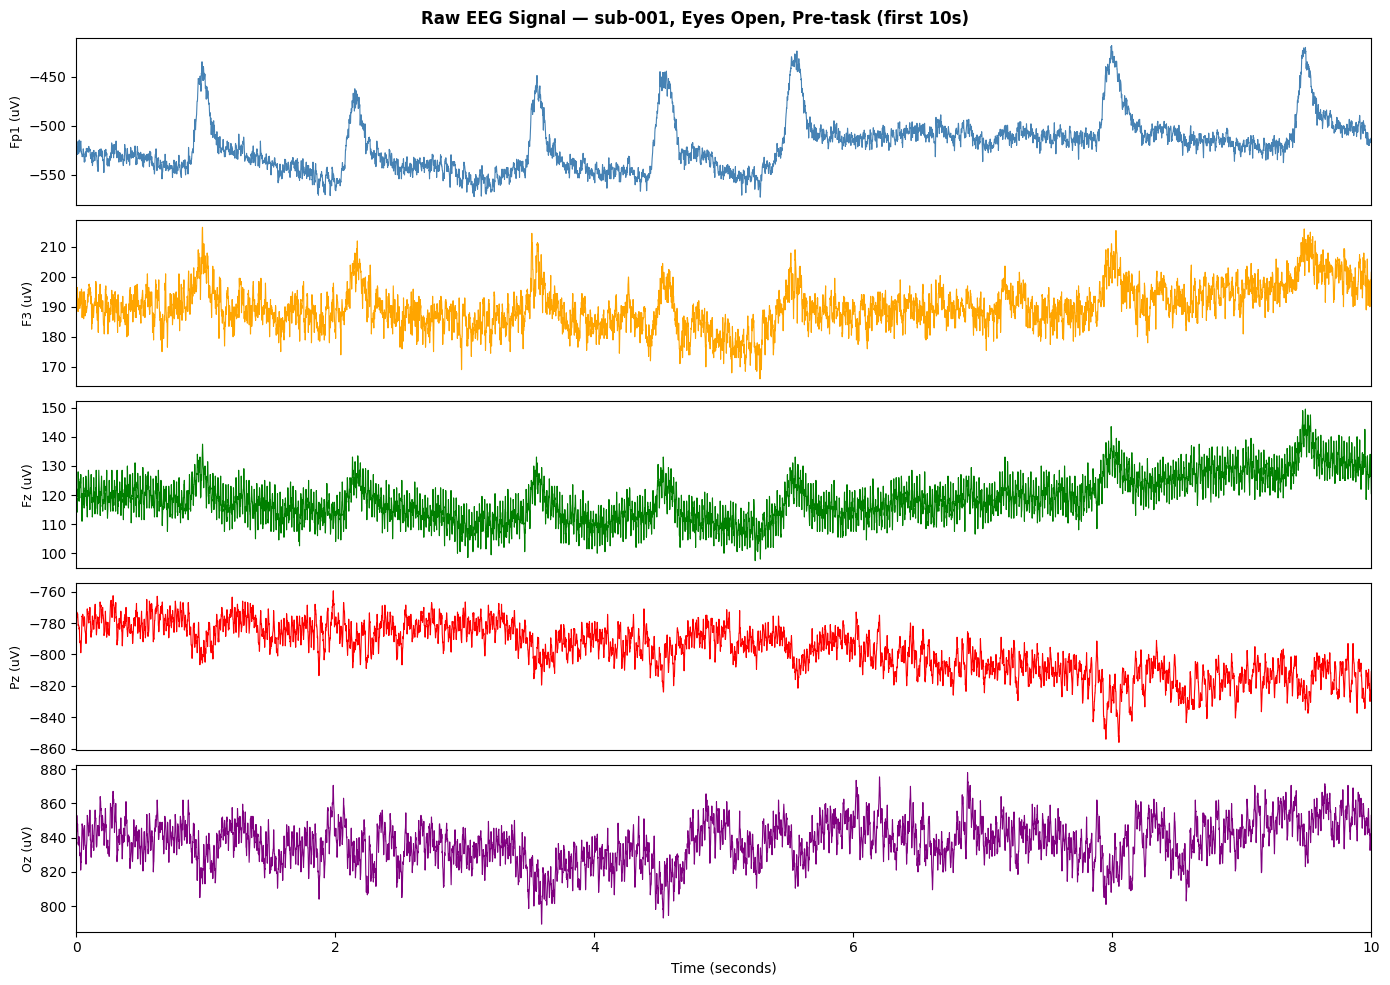

In [7]:
# Cell: Plot raw EEG signal
import mne

raw = mne.io.read_raw_edf(
    'Dataset/sub-001/ses-1/eeg/sub-001_ses-1_task-EyesOpen_acq-pre_eeg.edf',
    preload=True, verbose=False
)

fig, axes = plt.subplots(5, 1, figsize=(14, 10))
channels = ['Fp1', 'F3', 'Fz', 'Pz', 'Oz']
colors = ['steelblue', 'orange', 'green', 'red', 'purple']
time_mask = raw.times <= 10

for i, (ch, color) in enumerate(zip(channels, colors)):
    idx = raw.ch_names.index(ch)
    data = raw.get_data()[idx]
    axes[i].plot(raw.times[time_mask], data[time_mask] * 1e6,
                 color=color, linewidth=0.8)
    axes[i].set_ylabel(f'{ch} (uV)', fontsize=9)
    axes[i].set_xlim(0, 10)
    if i < 4:
        axes[i].set_xticks([])

axes[-1].set_xlabel('Time (seconds)')
plt.suptitle('Raw EEG Signal — sub-001, Eyes Open, Pre-task (first 10s)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/02_raw_eeg.png', dpi=150, bbox_inches='tight')
plt.show()

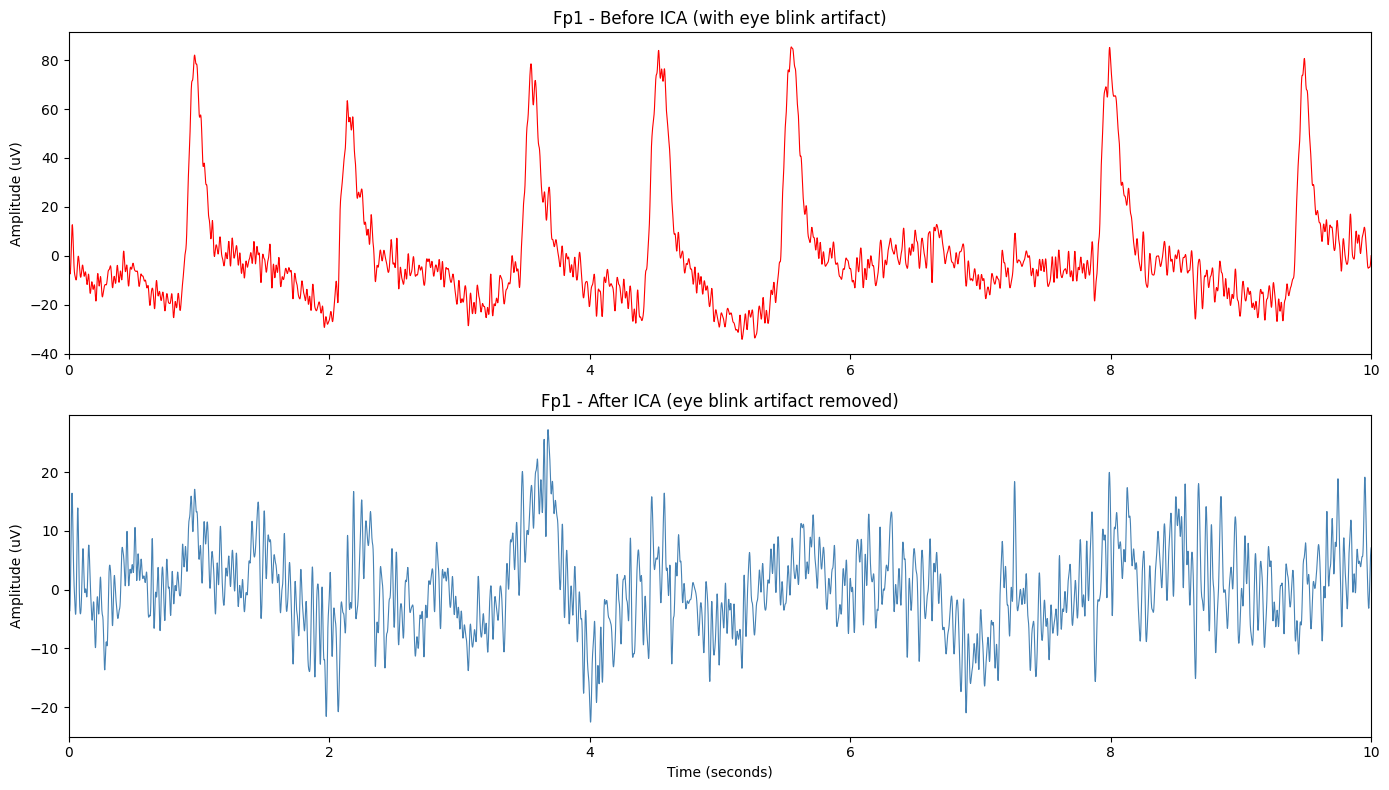

Removed 2 eye artifact components: [np.int64(2), np.int64(1)]


In [8]:
# Cell: Plot before vs after ICA
raw_filtered = raw.copy()
raw_filtered.filter(l_freq=0.5, h_freq=45.0, verbose=False)
raw_filtered.notch_filter(freqs=50, verbose=False)
raw_filtered.set_eeg_reference('average', verbose=False)

ica = ICA(n_components=20, random_state=42, verbose=False)
ica.fit(raw_filtered, verbose=False)
eog_indices, _ = ica.find_bads_eog(raw_filtered, ch_name='Fp1', verbose=False)
ica.exclude = eog_indices
raw_clean = raw_filtered.copy()
ica.apply(raw_clean, verbose=False)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
ch_idx = raw.ch_names.index('Fp1')

axes[0].plot(raw_filtered.times[time_mask],
             raw_filtered.get_data()[ch_idx][time_mask] * 1e6,
             color='red', linewidth=0.8)
axes[0].set_title('Fp1 - Before ICA (with eye blink artifact)')
axes[0].set_ylabel('Amplitude (uV)')
axes[0].set_xlim(0, 10)

axes[1].plot(raw_clean.times[time_mask],
             raw_clean.get_data()[ch_idx][time_mask] * 1e6,
             color='steelblue', linewidth=0.8)
axes[1].set_title('Fp1 - After ICA (eye blink artifact removed)')
axes[1].set_ylabel('Amplitude (uV)')
axes[1].set_xlabel('Time (seconds)')
axes[1].set_xlim(0, 10)

plt.tight_layout()
plt.savefig('outputs/02_ica_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Removed {len(eog_indices)} eye artifact components: {eog_indices}")

In [9]:
# Cell สุดท้าย: สร้าง features_final.csv จาก cache + demographics
import pandas as pd
import numpy as np

# โหลด participants ก่อน
participants = pd.read_csv('Dataset/participants.tsv', sep='\t')

def assign_age_group(age):
    if age <= 34:
        return 'Young (20-34)'
    elif age <= 50:
        return 'Middle (35-50)'
    else:
        return 'Older (51-70)'

participants['age_group'] = participants['age'].apply(assign_age_group)

df_final = pd.read_csv('features_raw.csv')

# ลบ demographic columns เก่าออกก่อน (ป้องกัน duplicate)
df_final = df_final.drop(
    columns=['age', 'sex', 'age_group'], errors='ignore'
)

# เพิ่ม theta_beta_ratio
df_final['theta_beta_ratio'] = (
    df_final['theta'] / df_final['beta'].replace(0, np.nan)
).fillna(0)

# Merge demographics
participants_clean = participants[['participant_id', 'age', 'sex', 'age_group']]
df_final = df_final.merge(
    participants_clean,
    left_on='subject',
    right_on='participant_id',
    how='left'
).drop(columns='participant_id')

# Save final dataset
df_final.to_csv('features_final.csv', index=False)

print("=== Final Dataset ===")
print(f"Shape: {df_final.shape}")
print(f"Columns: {df_final.columns.tolist()}")
print(f"\nLabel distribution:")
print(df_final['label'].value_counts())
print(f"\nAge group distribution:")
print(df_final['age_group'].value_counts().reindex(
    ['Young (20-34)', 'Middle (35-50)', 'Older (51-70)']
))
print("\nSaved to features_final.csv")

=== Final Dataset ===
Shape: (2432, 15)
Columns: ['delta', 'theta', 'low_alpha', 'high_alpha', 'alpha', 'beta', 'slow_fast_ratio', 'subject', 'condition', 'task', 'label', 'theta_beta_ratio', 'age', 'sex', 'age_group']

Label distribution:
label
0    1216
1    1216
Name: count, dtype: int64

Age group distribution:
age_group
Young (20-34)     812
Middle (35-50)    700
Older (51-70)     920
Name: count, dtype: int64

Saved to features_final.csv


In [10]:
print("\nNote: 'Status' is a stim channel, not EEG.")
print("features_raw.csv was extracted before the picks='eeg' fix (stim channel included).")
print("Checked on sub-001: difference ≤1.3% at beta. Results not expected to change materially.")


Note: 'Status' is a stim channel, not EEG.
features_raw.csv was extracted before the picks='eeg' fix (stim channel included).
Checked on sub-001: difference ≤1.3% at beta. Results not expected to change materially.


In [1]:
# ── ขยายการตรวจ stim channel จาก 1 ไฟล์เป็น 40 ไฟล์ ──
import glob, numpy as np, pandas as pd, mne
from mne.preprocessing import ICA
from scipy.signal import welch
mne.set_log_level('ERROR')

BANDS = {'delta': (1,4), 'theta': (4,8), 'low_alpha': (8,10),
         'high_alpha': (10,13), 'alpha': (8,13), 'beta': (13,30)}

def band_power(raw, picks, band):
    data = raw.get_data(picks=picks)
    sf   = raw.info['sfreq']
    out  = []
    for ch in data:
        f, psd = welch(ch, sf, nperseg=int(sf*2))
        tot  = psd[(f >= 1) & (f <= 45)].mean()
        bp   = psd[(f >= band[0]) & (f <= band[1])].mean()
        out.append(bp/tot if tot > 0 else 0)
    return float(np.mean(out))

files = sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*_eeg.edf'))
rng   = np.random.default_rng(42)
pick  = rng.choice(files, size=40, replace=False)

rows = []
for i, fp in enumerate(pick, 1):
    raw = mne.io.read_raw_edf(fp, preload=True, verbose=False)
    raw.filter(0.5, 45., verbose=False); raw.notch_filter(50, verbose=False)
    raw.set_eeg_reference('average', verbose=False)
    ica = ICA(n_components=20, random_state=42, verbose=False)
    ica.fit(raw, verbose=False)
    ica.exclude = ica.find_bads_eog(raw, ch_name='Fp1', verbose=False)[0]
    ica.apply(raw, verbose=False)
    for name, b in BANDS.items():
        a = band_power(raw, None,  b)     # ทุกช่อง รวม Status (แบบที่อยู่ใน cache)
        e = band_power(raw, 'eeg', b)     # เฉพาะ EEG (แบบที่ถูกต้อง)
        rows.append({'file': fp.split('/')[-1], 'band': name,
                     'all_ch': a, 'eeg_only': e,
                     'diff_pct': abs(a-e)/e*100 if e else np.nan})
    if i % 10 == 0:
        print(f"  {i}/40")

chk = pd.DataFrame(rows)
print("\n=== ผลต่างจากการรวมช่อง Status (40 ไฟล์สุ่ม) ===")
print(chk.groupby('band')['diff_pct'].agg(['mean','max']).round(3).to_string())
print(f"\nค่าสูงสุดที่พบทั้งหมด: {chk['diff_pct'].max():.3f}%")
print(f"ไฟล์ที่เกิน 2%: {(chk.groupby('file')['diff_pct'].max() > 2).sum()}/40")
chk.to_csv('outputs/stim_channel_check.csv', index=False)

/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/scipy/linalg/_basic.py:1622: RuntimeWarning: divide by zero encountered in matmul
  B = (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/scipy/linalg/_basic.py:1622: RuntimeWarning: overflow encountered in matmul
  B = (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/scipy/linalg/_basic.py:1622: RuntimeWarning: invalid value encountered in matmul
  B = (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/mne/utils/linalg.py:286: RuntimeWarning: divide by zero encountered in matmul
  return (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/mne/utils/linalg.py:286: RuntimeWarning: overflow encountered in matmul
  return (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/mne/utils/linalg.py:286: RuntimeWarning: invalid value encountered in matmul
 

  10/40


/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/scipy/linalg/_basic.py:1622: RuntimeWarning: divide by zero encountered in matmul
  B = (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/scipy/linalg/_basic.py:1622: RuntimeWarning: overflow encountered in matmul
  B = (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/scipy/linalg/_basic.py:1622: RuntimeWarning: invalid value encountered in matmul
  B = (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/mne/utils/linalg.py:286: RuntimeWarning: divide by zero encountered in matmul
  return (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/mne/utils/linalg.py:286: RuntimeWarning: overflow encountered in matmul
  return (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/mne/utils/linalg.py:286: RuntimeWarning: invalid value encountered in matmul
 

  20/40


/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/scipy/linalg/_basic.py:1622: RuntimeWarning: divide by zero encountered in matmul
  B = (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/scipy/linalg/_basic.py:1622: RuntimeWarning: overflow encountered in matmul
  B = (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/scipy/linalg/_basic.py:1622: RuntimeWarning: invalid value encountered in matmul
  B = (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/mne/utils/linalg.py:286: RuntimeWarning: divide by zero encountered in matmul
  return (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/mne/utils/linalg.py:286: RuntimeWarning: overflow encountered in matmul
  return (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/mne/utils/linalg.py:286: RuntimeWarning: invalid value encountered in matmul
 

  30/40


/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/scipy/linalg/_basic.py:1622: RuntimeWarning: divide by zero encountered in matmul
  B = (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/scipy/linalg/_basic.py:1622: RuntimeWarning: overflow encountered in matmul
  B = (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/scipy/linalg/_basic.py:1622: RuntimeWarning: invalid value encountered in matmul
  B = (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/mne/utils/linalg.py:286: RuntimeWarning: divide by zero encountered in matmul
  return (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/mne/utils/linalg.py:286: RuntimeWarning: overflow encountered in matmul
  return (u @ vh[:rank]).conj().T
/opt/miniconda3/envs/eeg-fatigue/lib/python3.10/site-packages/mne/utils/linalg.py:286: RuntimeWarning: invalid value encountered in matmul
 

  40/40

=== ผลต่างจากการรวมช่อง Status (40 ไฟล์สุ่ม) ===
             mean    max
band                    
alpha       1.234  5.925
beta        1.226  3.823
delta       2.131  6.856
high_alpha  1.241  7.175
low_alpha   1.212  4.645
theta       0.746  4.244

ค่าสูงสุดที่พบทั้งหมด: 7.175%
ไฟล์ที่เกิน 2%: 24/40


In [2]:
# ── วินิจฉัย RuntimeWarning ใน ICA ──
import warnings, glob, numpy as np, mne
from mne.preprocessing import ICA
mne.set_log_level('ERROR')

files = sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*_eeg.edf'))
pick  = np.random.default_rng(7).choice(files, size=8, replace=False)

def run_one(fp, drop_status, resample):
    raw = mne.io.read_raw_edf(fp, preload=True, verbose=False)
    if drop_status:
        st = [c for c, t in zip(raw.ch_names, raw.get_channel_types()) if t == 'stim']
        if st: raw.drop_channels(st)
    if resample:
        raw.resample(250, verbose=False)
    raw.filter(0.5, 45., verbose=False); raw.notch_filter(50, verbose=False)
    raw.set_eeg_reference('average', verbose=False)

    d = raw.get_data(picks='eeg')
    diag = {'n_nan': int(np.isnan(d).sum()), 'n_inf': int(np.isinf(d).sum()),
            'max_uV': float(np.abs(d).max() * 1e6),
            'n_flat': int((d.std(axis=1) < 1e-15).sum()),
            'rank': int(np.linalg.matrix_rank(d[:, ::10])), 'n_ch': d.shape[0]}

    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        ica = ICA(n_components=20, random_state=42, verbose=False)
        ica.fit(raw, verbose=False)
        ica.exclude = ica.find_bads_eog(raw, ch_name='Fp1', verbose=False)[0]
        ica.apply(raw, verbose=False)
        diag['n_runtimewarn'] = sum(1 for x in w if issubclass(x.category, RuntimeWarning))

    diag['mix_bad']   = int((~np.isfinite(ica.mixing_matrix_)).sum())
    out = raw.get_data(picks='eeg')
    diag['out_bad']   = int((~np.isfinite(out)).sum())
    diag['n_excl']    = len(ica.exclude)
    return diag

print(f"{'file':<46}{'cond':<18}{'warn':>5}{'rank':>6}{'flat':>5}"
      f"{'maxµV':>9}{'mixbad':>7}{'outbad':>7}")
print("-" * 103)
for fp in pick:
    for lab, ds, rs in [('as in NB2', False, False),
                        ('no Status', True,  False),
                        ('resample 250', True, True)]:
        d = run_one(fp, ds, rs)
        print(f"{fp.split('/')[-1][:44]:<46}{lab:<18}{d['n_runtimewarn']:>5}"
              f"{d['rank']:>4}/{d['n_ch']:<2}{d['n_flat']:>5}"
              f"{d['max_uV']:>9.0f}{d['mix_bad']:>7}{d['out_bad']:>7}")

file                                          cond               warn  rank flat    maxµV mixbad outbad
-------------------------------------------------------------------------------------------------------
sub-472_ses-1_task-EyesClosed_acq-post_eeg.e  as in NB2             9  63/64    0     6365      0      0
sub-472_ses-1_task-EyesClosed_acq-post_eeg.e  no Status             9  63/64    0     6365      0      0
sub-472_ses-1_task-EyesClosed_acq-post_eeg.e  resample 250          9  63/64    0     6270      0      0
sub-507_ses-1_task-EyesOpen_acq-post_eeg.edf  as in NB2             9  63/64    0     2808      0      0
sub-507_ses-1_task-EyesOpen_acq-post_eeg.edf  no Status             9  63/64    0     2808      0      0
sub-507_ses-1_task-EyesOpen_acq-post_eeg.edf  resample 250          9  63/64    0     2759      0      0
sub-137_ses-1_task-EyesOpen_acq-pre_eeg.edf   as in NB2             9  63/64    0     3435      0      0
sub-137_ses-1_task-EyesOpen_acq-pre_eeg.edf   no Status  